# Check trial-aligned extraction

Sanity-checks the output of `src/data/ingestion.py` for one session: plots the population-averaged neural PSTH and the DLC jaw traces for a single hit trial, to confirm the alignment around `stim_onset` looks sane.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

d = np.load("../data/processed/AB151_20250128_123409_aligned.npz", allow_pickle=True)
print({k: d[k].shape if hasattr(d[k], 'shape') else d[k] for k in d.files})

{'neural': (777, 500, 608), 'time_neural': (500,), 'unit_ids': (608,), 'dlc': (777, 1000, 2), 'time_dlc': (1000,), 'bodyparts': (2,), 'trial_type': (777,), 'lick_flag': (777,), 'context': (777,), 'subject_id': (), 'session_id': ()}


trial_idx: 123 | trial_type: whisker_trial | lick_flag: 1


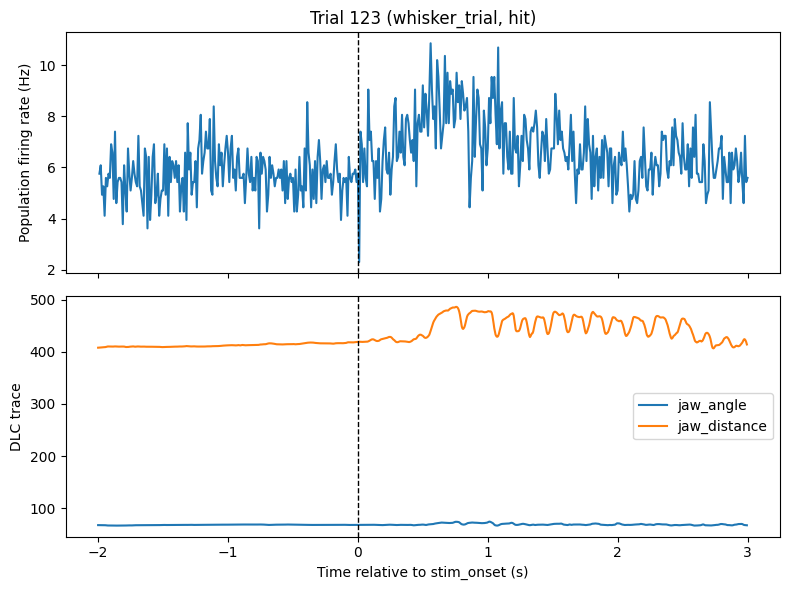

In [2]:
# Pick a whisker-trial hit to spot-check
trial_idx = np.where((d["trial_type"] == "whisker_trial") & (d["lick_flag"] == 1))[0][0]
print("trial_idx:", trial_idx, "| trial_type:", d["trial_type"][trial_idx], "| lick_flag:", d["lick_flag"][trial_idx])

fig, axes = plt.subplots(2, 1, figsize=(8, 6), sharex=True)

population_rate = d["neural"][trial_idx].mean(axis=-1)  # mean firing rate (Hz) across good units
axes[0].plot(d["time_neural"], population_rate)
axes[0].axvline(0, color="k", linestyle="--", linewidth=1)
axes[0].set_ylabel("Population firing rate (Hz)")
axes[0].set_title(f"Trial {trial_idx} ({d['trial_type'][trial_idx]}, hit)")

for bp_idx, bp in enumerate(d["bodyparts"]):
    axes[1].plot(d["time_dlc"], d["dlc"][trial_idx, :, bp_idx], label=bp)
axes[1].axvline(0, color="k", linestyle="--", linewidth=1)
axes[1].set_ylabel("DLC trace")
axes[1].set_xlabel("Time relative to stim_onset (s)")
axes[1].legend()

plt.tight_layout()
plt.show()